# RO1 | Descriptive & Comparative Analysis
## American Airlines On-Time Performance at Charlotte Douglas (CLT), 2025

**Research objective:** Identify which routes, destination airports, days, months, and scheduled departure periods have the highest rates of delays and cancellations.

**Business question:** Where should American Airlines look first to improve on-time performance at its Charlotte hub?

**Scope:** 2025 BTS *Reporting Carrier On-Time Performance* data; AA-operated flights with `ORIGIN == "CLT"` **or** `DEST == "CLT"`. We use **departures from CLT** for scheduled departure-period, weekday, destination, and cancellation comparisons, while keeping arrivals for hub context.

> **Measure definitions:** A late arrival is **15+ minutes after scheduled arrival**, among completed, non-diverted flights with valid `ARR_DELAY`. Cancellation rates use **all scheduled flight records** in each group. Rates with different denominators should not be confused.

### 1 | Import packages and locate the prepared master CSV

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

BLUE = "#325AD6"
DARK_BLUE = "#2447B9"
ORANGE = "#D14000"
GRAY = "#64748B"
LIGHT_BLUE = "#EAF3FF"

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "font.size": 11,
})

paths = [
    Path("../Data/AA_CLT_2025.csv"),
    Path("Data/AA_CLT_2025.csv"),
    Path("AA_CLT_2025.csv"),
]
data_path = next((p for p in paths if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError(
        "Could not find Data/AA_CLT_2025.csv. "
        "Run DataCleaning_Prep.py or update the path above."
    )

df = pd.read_csv(data_path, low_memory=False)
print(f"Loaded {len(df):,} flights and {df.shape[1]} columns from {data_path}")

Loaded 235,819 flights and 73 columns from ../Data/AA_CLT_2025.csv


### 2 | Validate the scope and create analysis columns

The `DIRECTION` field tells us whether a record is an inbound or outbound flight. We **retain** cancellations and diversions in the master dataset; we only exclude them from arrival-delay rate denominators. Scheduled departure time is local to each flight's **origin airport**, so our time-of-day comparisons specifically use **CLT departures**.

In [2]:
required = {
    "YEAR", "MONTH", "DAY_OF_WEEK", "OP_CARRIER", "ORIGIN", "DEST",
    "FL_DATE", "CRS_DEP_TIME", "ARR_DELAY", "CANCELLED", "DIVERTED",
    "CANCELLATION_CODE", "CARRIER_DELAY", "WEATHER_DELAY", "NAS_DELAY",
    "SECURITY_DELAY", "LATE_AIRCRAFT_DELAY"
}
missing = sorted(required - set(df.columns))
if missing:
    raise ValueError(f"Missing required BTS columns: {missing}")

assert df["YEAR"].eq(2025).all(), "Year outside 2025 found"
assert df["OP_CARRIER"].eq("AA").all(), "Other operating airline found"
assert (df["ORIGIN"].eq("CLT") | df["DEST"].eq("CLT")).all(), "Non-CLT flight found"

df["DIRECTION"] = np.where(df["ORIGIN"].eq("CLT"), "Departing CLT", "Arriving CLT")
df["FL_DATE"] = pd.to_datetime(df["FL_DATE"], errors="coerce")
df["SCHED_DEP_HOUR"] = (pd.to_numeric(df["CRS_DEP_TIME"], errors="coerce") // 100) % 24
period_order = ["Overnight", "Morning", "Afternoon", "Evening"]
df["DEPARTURE_PERIOD"] = pd.cut(
    df["SCHED_DEP_HOUR"], bins=[-1, 5, 11, 17, 23], labels=period_order
)
day_names = {1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat", 7: "Sun"}
df["DAY"] = df["DAY_OF_WEEK"].map(day_names)
df["COMPLETED"] = (
    df["CANCELLED"].eq(0) & df["DIVERTED"].eq(0) & df["ARR_DELAY"].notna()
)
df["LATE15"] = df["COMPLETED"] & df["ARR_DELAY"].ge(15)

qa = pd.Series({
    "Flight records": len(df),
    "2025 months represented": df["MONTH"].nunique(),
    "Distinct flight dates": df["FL_DATE"].nunique(),
    "Departures from CLT": df["ORIGIN"].eq("CLT").sum(),
    "Arrivals at CLT": df["DEST"].eq("CLT").sum(),
    "Missing scheduled hours": df["SCHED_DEP_HOUR"].isna().sum(),
    "Missing flight dates": df["FL_DATE"].isna().sum(),
})
display(qa.to_frame("Count"))

/var/folders/tg/f1p8cfrs373gy3xgykv2pysh0000gn/T/ipykernel_48082/3023356484.py:16: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["FL_DATE"] = pd.to_datetime(df["FL_DATE"], errors="coerce")


,Count
Flight records,235819
2025 months represented,12
Distinct flight dates,365
Departures from CLT,117906
Arrivals at CLT,117913
Missing scheduled hours,0
Missing flight dates,0


### 3 | Compare inbound and outbound performance

The same `ARR_DELAY` measure represents arrival **at CLT** for inbound flights and arrival **at another airport** for outbound flights. Differences describe the network; they do not by themselves prove CLT caused the delays.

,flights,completed,late_arrivals,cancelled,diverted,arrival_delay_rate_pct,cancellation_rate_pct
DIRECTION,,,,,,,
Arriving CLT,117913,116148,21679,1620.0,145.0,18.66,1.37
Departing CLT,117906,116128,29743,1510.0,268.0,25.61,1.28


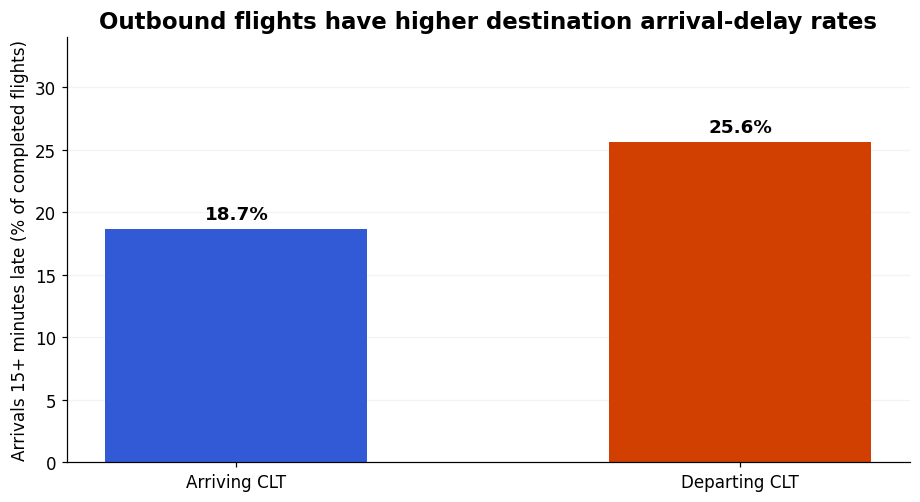

In [3]:
direction_summary = df.groupby("DIRECTION").agg(
    flights=("YEAR", "size"),
    completed=("COMPLETED", "sum"),
    late_arrivals=("LATE15", "sum"),
    cancelled=("CANCELLED", "sum"),
    diverted=("DIVERTED", "sum")
)
direction_summary["arrival_delay_rate_pct"] = 100 * direction_summary["late_arrivals"] / direction_summary["completed"]
direction_summary["cancellation_rate_pct"] = 100 * direction_summary["cancelled"] / direction_summary["flights"]
display(direction_summary.round(2))

fig, ax = plt.subplots(figsize=(8.5, 4.7))
vals = direction_summary.reindex(["Arriving CLT", "Departing CLT"])["arrival_delay_rate_pct"]
bars = ax.bar(vals.index, vals, color=[BLUE, ORANGE], width=0.52)
ax.bar_label(bars, fmt="%.1f%%", padding=4, fontsize=12, weight="bold")
ax.set_title("Outbound flights have higher destination arrival-delay rates")
ax.set_ylabel("Arrivals 15+ minutes late (% of completed flights)")
ax.set_ylim(0, 34)
ax.grid(axis="y", alpha=.15)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

### 4 | Focus on AA flights departing CLT

These 2025 outbound flights form the main comparison population for RO1 and line up with RO2's arrival-delay regression. All cancellation calculations continue to include cancelled departures.

In [4]:
outbound = df[df["DIRECTION"].eq("Departing CLT")].copy()
print(f"Outbound scheduled flights: {len(outbound):,}")
print(f"Completed, valid arrivals: {outbound['COMPLETED'].sum():,}")
print(f"Arrival delays >= 15 min: {outbound['LATE15'].sum():,}")
print(f"Cancelled departures: {int(outbound['CANCELLED'].sum()):,}")
print(f"Diversions: {int(outbound['DIVERTED'].sum()):,}")

Outbound scheduled flights: 117,906
Completed, valid arrivals: 116,128
Arrival delays >= 15 min: 29,743
Cancelled departures: 1,510
Diversions: 268


### 5 | Which departure periods have the worst reliability?

We compare **rates** (risk per completed flight) with **counts** (total number of late arrivals). Both matter: a high-rate time period may affect fewer flights than a moderate-rate, high-volume period.

,flights,completed,late_arrivals,cancelled,arrival_delay_rate_pct,cancellation_rate_pct
DEPARTURE_PERIOD,,,,,,
Overnight,575,570,60,5.0,10.53,0.87
Morning,37011,36650,5426,296.0,14.80,0.80
Afternoon,37702,37232,10398,361.0,27.93,0.96
Evening,42618,41676,13859,848.0,33.25,1.99


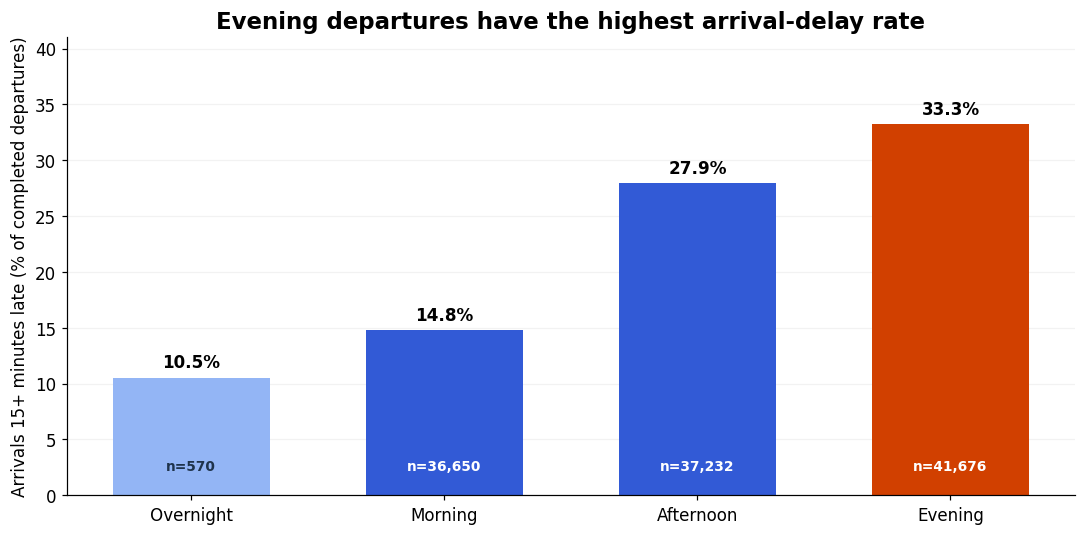

Evening share of all departures: 36.1%
Evening share of delayed arrivals: 46.6%


In [5]:
period_summary = outbound.groupby("DEPARTURE_PERIOD", observed=True).agg(
    flights=("YEAR", "size"), completed=("COMPLETED", "sum"),
    late_arrivals=("LATE15", "sum"), cancelled=("CANCELLED", "sum")
).reindex(period_order)
period_summary["arrival_delay_rate_pct"] = 100 * period_summary["late_arrivals"] / period_summary["completed"]
period_summary["cancellation_rate_pct"] = 100 * period_summary["cancelled"] / period_summary["flights"]
display(period_summary.round(2))

fig, ax = plt.subplots(figsize=(10, 5))
colors = ["#93B5F5", BLUE, BLUE, ORANGE]
bars = ax.bar(period_summary.index, period_summary["arrival_delay_rate_pct"], color=colors, width=.62)
ax.bar_label(bars, fmt="%.1f%%", padding=4, weight="bold")
ax.set_title("Evening departures have the highest arrival-delay rate")
ax.set_ylabel("Arrivals 15+ minutes late (% of completed departures)")
ax.set_ylim(0, 41)
ax.grid(axis="y", alpha=.16)
ax.set_axisbelow(True)
for i, (_, r) in enumerate(period_summary.iterrows()):
    ax.text(i, 2, f"n={int(r['completed']):,}", ha="center", va="bottom", fontsize=9,
            color="white" if i > 0 else "#1F334B", weight="bold")
plt.tight_layout()
plt.show()

share_flights = 100 * period_summary.loc["Evening", "flights"] / len(outbound)
share_late = 100 * period_summary.loc["Evening", "late_arrivals"] / outbound["LATE15"].sum()
print(f"Evening share of all departures: {share_flights:.1f}%")
print(f"Evening share of delayed arrivals: {share_late:.1f}%")

### 6 | Does performance change across the year?

A full calendar year allows comparison of seasonality; it does **not** establish whether 2025 improved or deteriorated relative to other years.

,flights,completed,late_arrivals,cancelled,arrival_delay_rate_pct,cancellation_rate_pct
MONTH,,,,,,
1,9862,9479,1779,360.0,18.77,3.65
2,9150,8977,1964,159.0,21.88,1.74
3,10561,10413,2488,124.0,23.89,1.17
4,9983,9933,2530,30.0,25.47,0.30
5,10434,10312,2720,98.0,26.38,0.94
6,9933,9643,3515,264.0,36.45,2.66
7,10137,9865,3774,232.0,38.26,2.29
8,9480,9373,2952,77.0,31.49,0.81
9,9228,9176,1624,31.0,17.70,0.34


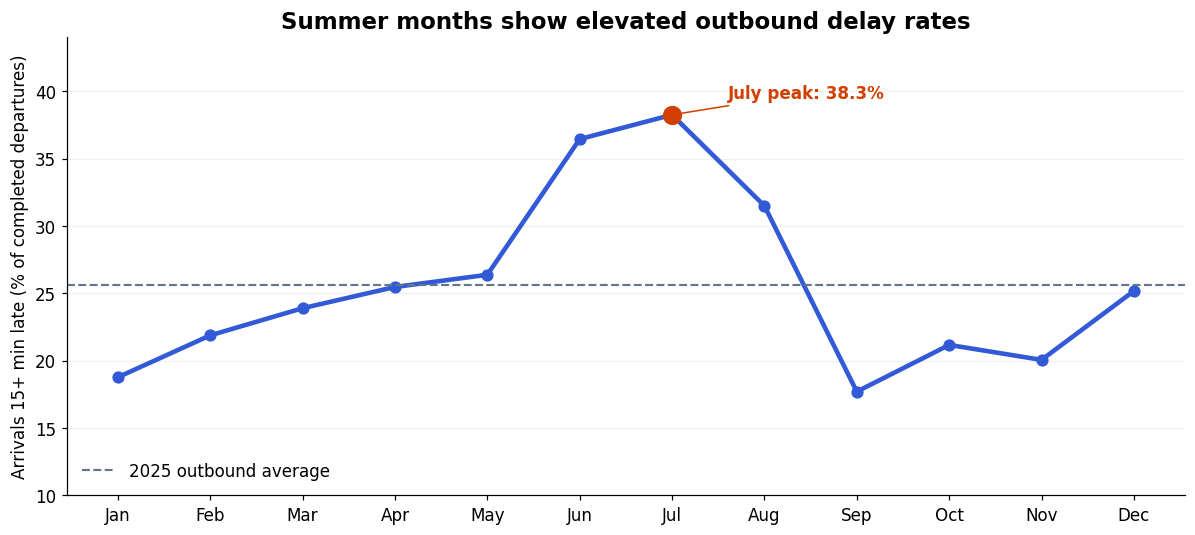

In [6]:
monthly = outbound.groupby("MONTH").agg(
    flights=("YEAR", "size"), completed=("COMPLETED", "sum"),
    late_arrivals=("LATE15", "sum"), cancelled=("CANCELLED", "sum")
).reindex(range(1, 13))
monthly["arrival_delay_rate_pct"] = 100 * monthly["late_arrivals"] / monthly["completed"]
monthly["cancellation_rate_pct"] = 100 * monthly["cancelled"] / monthly["flights"]
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
display(monthly.round(2))

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(monthly.index, monthly["arrival_delay_rate_pct"], lw=3, color=BLUE, marker="o", markersize=7)
ax.axhline(100 * outbound["LATE15"].sum() / outbound["COMPLETED"].sum(),
           color=GRAY, linestyle="--", linewidth=1.4, label="2025 outbound average")
ax.scatter([7], [monthly.loc[7, "arrival_delay_rate_pct"]], color=ORANGE, s=135, zorder=4)
ax.annotate(f"July peak: {monthly.loc[7, 'arrival_delay_rate_pct']:.1f}%",
            (7, monthly.loc[7, "arrival_delay_rate_pct"]), xytext=(7.6, 39.5),
            fontsize=11, weight="bold", color=ORANGE,
            arrowprops={"arrowstyle":"-", "color": ORANGE})
ax.set_xticks(range(1,13), month_labels)
ax.set_ylim(10, 44)
ax.set_ylabel("Arrivals 15+ min late (% of completed departures)")
ax.set_title("Summer months show elevated outbound delay rates")
ax.grid(axis="y", alpha=.18)
ax.legend(frameon=False, loc="lower left")
plt.tight_layout()
plt.show()

### 7 | Which weekdays and hours have the highest delay rates?

The heatmap focuses on **morning, afternoon, and evening** because the overnight sample is small. This is a *descriptive* comparison; differences may partly reflect month, routes, and other operating conditions.

,flights,completed,late_arrivals,cancelled,arrival_delay_rate_pct,cancellation_rate_pct
DAY,,,,,,
Mon,17191,16971,4881,182.0,28.76,1.06
Tue,16316,16165,3245,117.0,20.07,0.72
Wed,16579,16323,3242,226.0,19.86,1.36
Thu,17419,17113,4794,250.0,28.01,1.44
Fri,16984,16619,4404,331.0,26.50,1.95
Sat,15733,15517,3685,190.0,23.75,1.21
Sun,17684,17420,5492,214.0,31.53,1.21


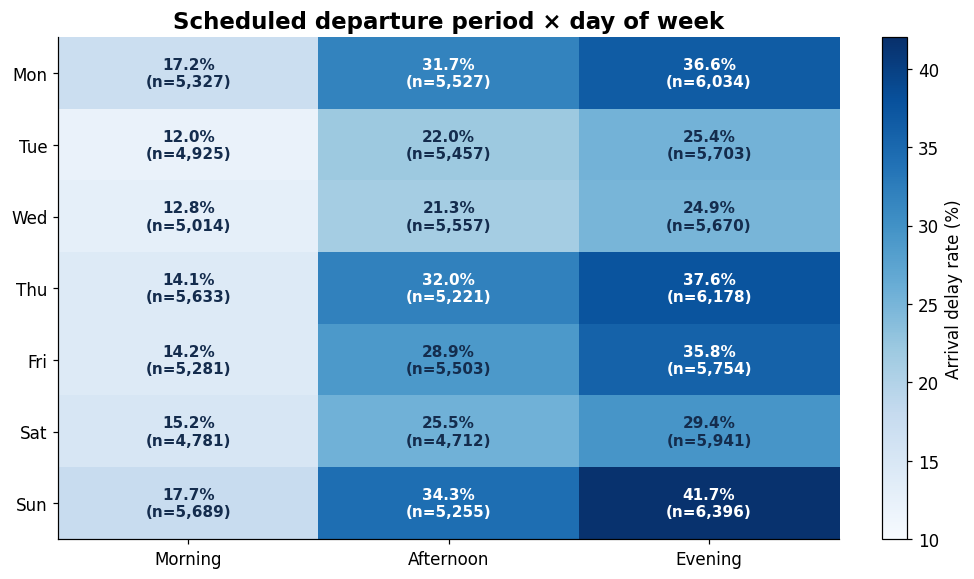

In [7]:
day_order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday = outbound.groupby("DAY").agg(
    flights=("YEAR", "size"), completed=("COMPLETED", "sum"),
    late_arrivals=("LATE15", "sum"), cancelled=("CANCELLED", "sum")
).reindex(day_order)
weekday["arrival_delay_rate_pct"] = 100*weekday["late_arrivals"]/weekday["completed"]
weekday["cancellation_rate_pct"] = 100*weekday["cancelled"]/weekday["flights"]
display(weekday.round(2))

matrix = outbound[outbound["DEPARTURE_PERIOD"].isin(["Morning", "Afternoon", "Evening"])].groupby(
    ["DAY", "DEPARTURE_PERIOD"], observed=True
).agg(completed=("COMPLETED", "sum"), late=("LATE15", "sum"))
matrix["rate"] = 100 * matrix["late"] / matrix["completed"]
heat = matrix["rate"].unstack().reindex(index=day_order, columns=["Morning", "Afternoon", "Evening"])
counts = matrix["completed"].unstack().reindex(index=day_order, columns=["Morning", "Afternoon", "Evening"])

fig, ax = plt.subplots(figsize=(9, 5.4))
im = ax.imshow(heat.to_numpy(), cmap="Blues", vmin=10, vmax=42, aspect="auto")
ax.set_xticks(range(3), heat.columns)
ax.set_yticks(range(7), heat.index)
for r in range(7):
    for c in range(3):
        v = heat.iat[r, c]
        ax.text(c, r, f"{v:.1f}%\n(n={counts.iat[r,c]:,.0f})",
                ha="center", va="center", fontsize=10,
                color="white" if v > 30 else "#142C4D", weight="bold")
ax.set_title("Scheduled departure period × day of week")
fig.colorbar(im, ax=ax, fraction=.04, label="Arrival delay rate (%)")
plt.tight_layout()
plt.show()

### 8 | Which destinations deserve attention?

Because every outbound record originates at CLT, route comparisons are **CLT → destination** comparisons. We report both:

- **Rate:** the share arriving ≥15 minutes late, using at least 300 completed flights to avoid ranking very small samples.
- **Burden:** the number of delayed arrivals, which reflects how many flights are affected in total.

A high rate does not automatically mean the largest systemwide impact.

Top ten destinations by late arrivals (total burden):


,scheduled,completed,late_arrivals,cancelled,arrival_delay_rate_pct,cancellation_rate_pct
DEST,,,,,,
MCO,3881,3826,1067,45.0,27.89,1.16
LGA,3162,3058,988,86.0,32.31,2.72
DFW,3709,3621,886,74.0,24.47,2.00
MIA,3347,3303,857,36.0,25.95,1.08
DCA,2533,2462,824,63.0,33.47,2.49
BOS,2795,2756,792,36.0,28.74,1.29
ORD,2999,2944,790,48.0,26.83,1.60
TPA,3306,3262,773,38.0,23.70,1.15
RDU,3316,3266,727,50.0,22.26,1.51


Highest late-arrival rates among destinations with >=300 completed flights:


,scheduled,completed,late_arrivals,cancelled,arrival_delay_rate_pct,cancellation_rate_pct
DEST,,,,,,
AVL,372,362,135,6.0,37.29,1.61
EWR,1828,1769,646,51.0,36.52,2.79
PDX,391,387,130,3.0,33.59,0.77
DCA,2533,2462,824,63.0,33.47,2.49
ATL,388,381,125,6.0,32.81,1.55
CID,393,387,126,4.0,32.56,1.02
JFK,1770,1743,567,24.0,32.53,1.36
LGA,3162,3058,988,86.0,32.31,2.72
SAV,748,735,231,10.0,31.43,1.34


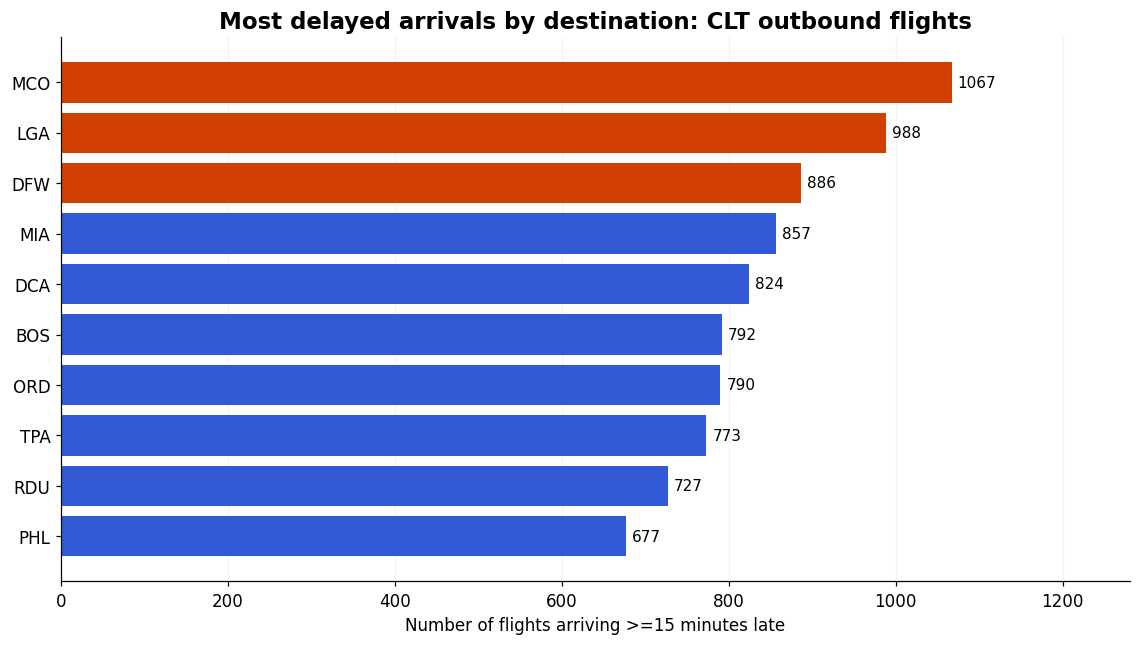

In [8]:
destinations = outbound.groupby("DEST").agg(
    scheduled=("YEAR", "size"), completed=("COMPLETED", "sum"),
    late_arrivals=("LATE15", "sum"), cancelled=("CANCELLED", "sum")
)
destinations["arrival_delay_rate_pct"] = 100 * destinations["late_arrivals"] / destinations["completed"]
destinations["cancellation_rate_pct"] = 100 * destinations["cancelled"] / destinations["scheduled"]
print("Top ten destinations by late arrivals (total burden):")
display(destinations.sort_values("late_arrivals", ascending=False).head(10).round(2))
print("Highest late-arrival rates among destinations with >=300 completed flights:")
display(destinations[destinations["completed"] >= 300]
        .sort_values("arrival_delay_rate_pct", ascending=False).head(10).round(2))

impact = destinations.sort_values("late_arrivals", ascending=False).head(10).sort_values("late_arrivals")
fig, ax = plt.subplots(figsize=(10.5, 6))
barcolors = [ORANGE if code in ["MCO", "LGA", "DFW"] else BLUE for code in impact.index]
bars = ax.barh(impact.index, impact["late_arrivals"], color=barcolors)
ax.bar_label(bars, padding=4, fontsize=10)
ax.set_xlim(0, impact["late_arrivals"].max()*1.2)
ax.set_title("Most delayed arrivals by destination: CLT outbound flights")
ax.set_xlabel("Number of flights arriving >=15 minutes late")
ax.grid(axis="x", alpha=.15)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

### 9 | Cancellations and reported delay categories

A cancellation is **not** an on-time arrival. We analyze cancellation rates separately. BTS cancellation codes are `A` carrier, `B` weather, `C` National Aviation System, and `D` security. Delay-cause minute fields are typically populated only for flights arriving ≥15 minutes late, so they should not be interpreted as reasons for *all* flights or as direct causal proof.

Cancellation reasons (outbound flights):


,Cancelled flights
CANCELLATION_CODE,
Weather,1305
Carrier,119
NAS,86


,reported_minutes,share_pct
Late aircraft,879571,44.4
Carrier,583190,29.5
NAS,349202,17.6
Weather,162260,8.2
Security,5123,0.3


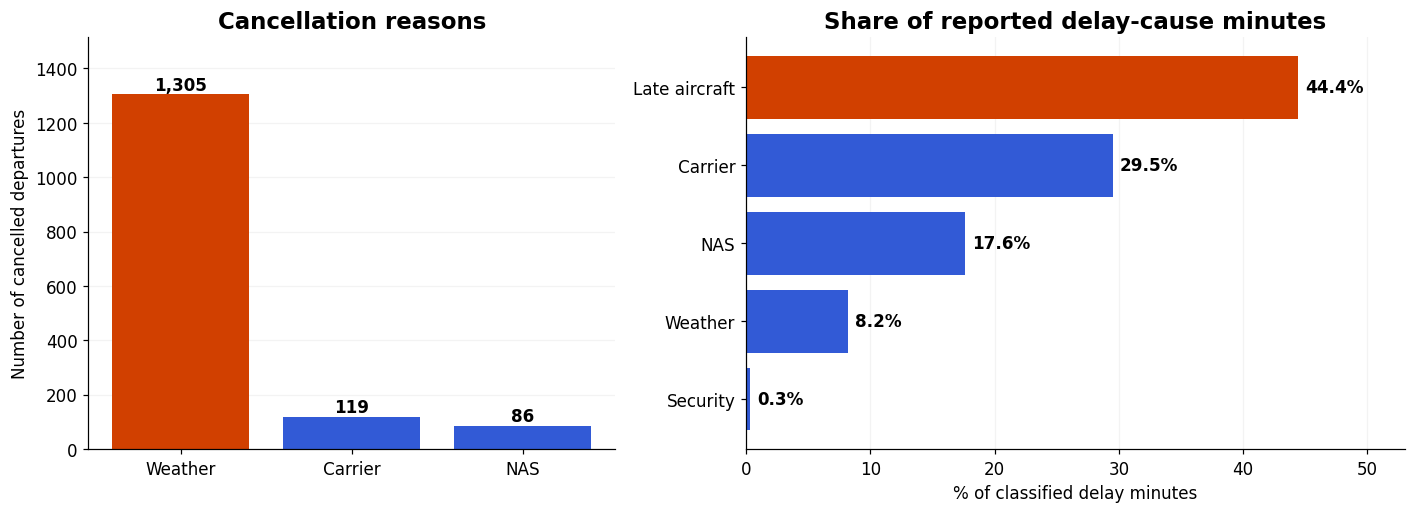

In [9]:
codes = {"A": "Carrier", "B": "Weather", "C": "NAS", "D": "Security"}
cancel_counts = outbound.loc[outbound["CANCELLED"].eq(1), "CANCELLATION_CODE"].map(codes).value_counts()
print("Cancellation reasons (outbound flights):")
display(cancel_counts.to_frame("Cancelled flights"))

cause_cols = {
    "CARRIER_DELAY": "Carrier",
    "WEATHER_DELAY": "Weather",
    "NAS_DELAY": "NAS",
    "SECURITY_DELAY": "Security",
    "LATE_AIRCRAFT_DELAY": "Late aircraft"
}
cause_minutes = outbound[list(cause_cols)].sum().rename(index=cause_cols).sort_values(ascending=False)
cause_share = (100 * cause_minutes / cause_minutes.sum()).round(1)
display(pd.DataFrame({"reported_minutes": cause_minutes.astype(int), "share_pct": cause_share}))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.25]})
axs[0].bar(cancel_counts.index, cancel_counts.values, color=[ORANGE if x == "Weather" else BLUE for x in cancel_counts.index])
axs[0].set_title("Cancellation reasons")
axs[0].set_ylabel("Number of cancelled departures")
axs[0].grid(axis="y", alpha=.15)
for i, v in enumerate(cancel_counts.values):
    axs[0].text(i, v+15, f"{v:,}", ha="center", weight="bold")
axs[0].set_ylim(0, cancel_counts.max()*1.16)
axs[1].barh(cause_share.index[::-1], cause_share.values[::-1],
            color=[ORANGE if name=="Late aircraft" else BLUE for name in cause_share.index[::-1]])
for i, v in enumerate(cause_share.values[::-1]):
    axs[1].text(v+.6, i, f"{v:.1f}%", va="center", weight="bold")
axs[1].set_xlim(0, 53)
axs[1].set_title("Share of reported delay-cause minutes")
axs[1].set_xlabel("% of classified delay minutes")
axs[1].grid(axis="x", alpha=.15)
for ax in axs: ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

### 10 | Sensitivity: does the evening pattern depend on the delay threshold?

Compare 15, 30, and 60 minutes late, with the **same completed-flight denominator**. This checks whether the evening pattern persists for more severe delays.

threshold,15,30,60
period,,,
Overnight,10.53,4.91,2.63
Morning,14.80,8.50,4.13
Afternoon,27.93,18.68,9.86
Evening,33.25,23.01,12.56


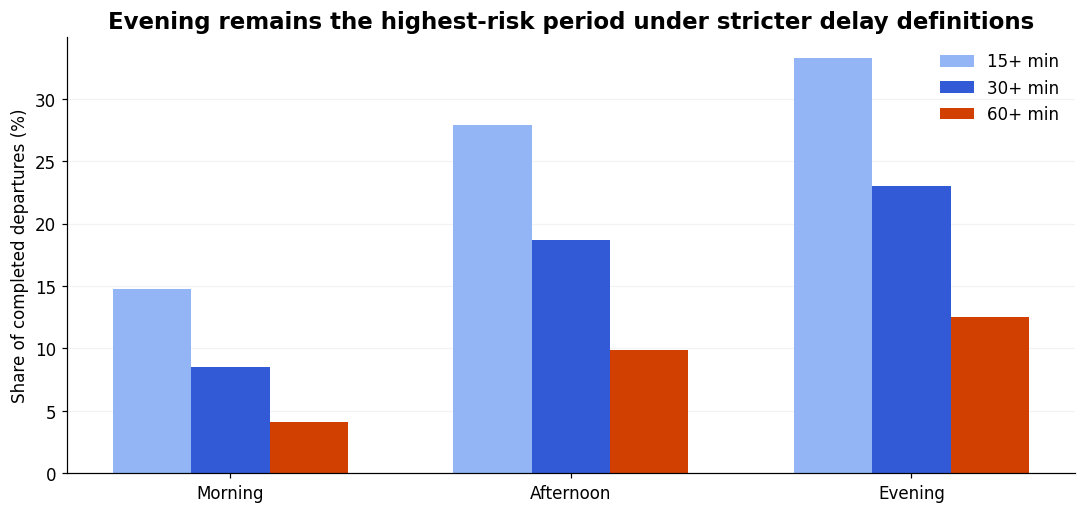

In [10]:
thresholds = [15, 30, 60]
rows = []
for period, group in outbound.groupby("DEPARTURE_PERIOD", observed=True):
    n = int(group["COMPLETED"].sum())
    for t in thresholds:
        count = int((group["COMPLETED"] & group["ARR_DELAY"].ge(t)).sum())
        rows.append({"period": str(period), "threshold": t, "completed": n,
                     "late_count": count, "rate_pct": 100*count/n})
sensitivity = pd.DataFrame(rows)
display(sensitivity.pivot(index="period", columns="threshold", values="rate_pct")
        .reindex(period_order).round(2))

fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(3)
w = .23
for j, t in enumerate(thresholds):
    series = sensitivity[(sensitivity.threshold==t) & sensitivity.period.isin(["Morning", "Afternoon", "Evening"])].set_index("period").reindex(["Morning", "Afternoon", "Evening"])
    ax.bar(x+(j-1)*w, series.rate_pct, width=w, label=f"{t}+ min", color=["#93B5F5", BLUE, ORANGE][j])
ax.set_xticks(x, ["Morning", "Afternoon", "Evening"])
ax.set_ylabel("Share of completed departures (%)")
ax.set_title("Evening remains the highest-risk period under stricter delay definitions")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=.15)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## RO1 conclusion: where should management investigate first?

**Evidence from descriptive comparisons (not causal conclusions):**

1. **Departure time:** Evening flights from CLT had a **33.3%** arrival delay rate versus **14.8%** for morning flights. Evening departures account for a disproportionate share of delayed arrivals relative to their scheduled flight volume.
2. **Season:** The outbound delay rate peaked in **July (38.3%)**, compared with **September (17.7%)**.
3. **Destinations:** Route-level **rates** and total delayed-flight **counts** highlight different priorities. The notebook reports both, with a minimum-volume filter for rate rankings.
4. **Cause reporting:** Late-aircraft and carrier-related delay minutes suggest topics for closer investigation, while weather dominates the coded outbound cancellations.

**Management implication:** Prioritize investigation of *evening* and *summer* operations, then use route-level volume and disruption categories to target pilot interventions. RO2 regression and RO3 clustering should test and refine these priorities before proposing specific operational changes.

**Limitations:** Only AA-operated flights at CLT in 2025; regional American Eagle operations may be excluded. BTS categories do not directly capture passenger connections, gate availability, crew schedules, or causal mechanisms. Scheduled departure times for inbound flights are local to their origin, so inbound times are not used as CLT departure-period measures.

**Reproducibility:** Input is the team's `Data/AA_CLT_2025.csv`; no changes are made to the source CSV. All charts and tables regenerate when this notebook is run top-to-bottom.